# Data Exploration and Preprocessing

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

## Dataset Overview

In [6]:
data_path = '../data/raw/'
classes = ['paper', 'rock', 'scissors']

class_counts = {}
for class_name in classes:
    class_path = os.path.join(data_path, class_name)
    class_counts[class_name] = len(os.listdir(class_path))

print("Class distribution:")
for class_name, count in class_counts.items():
    print(f"  {class_name}: {count} images")
print(f"\nTotal images: {sum(class_counts.values())}")

Class distribution:
  paper: 712 images
  rock: 726 images
  scissors: 750 images

Total images: 2188


## Sample Images

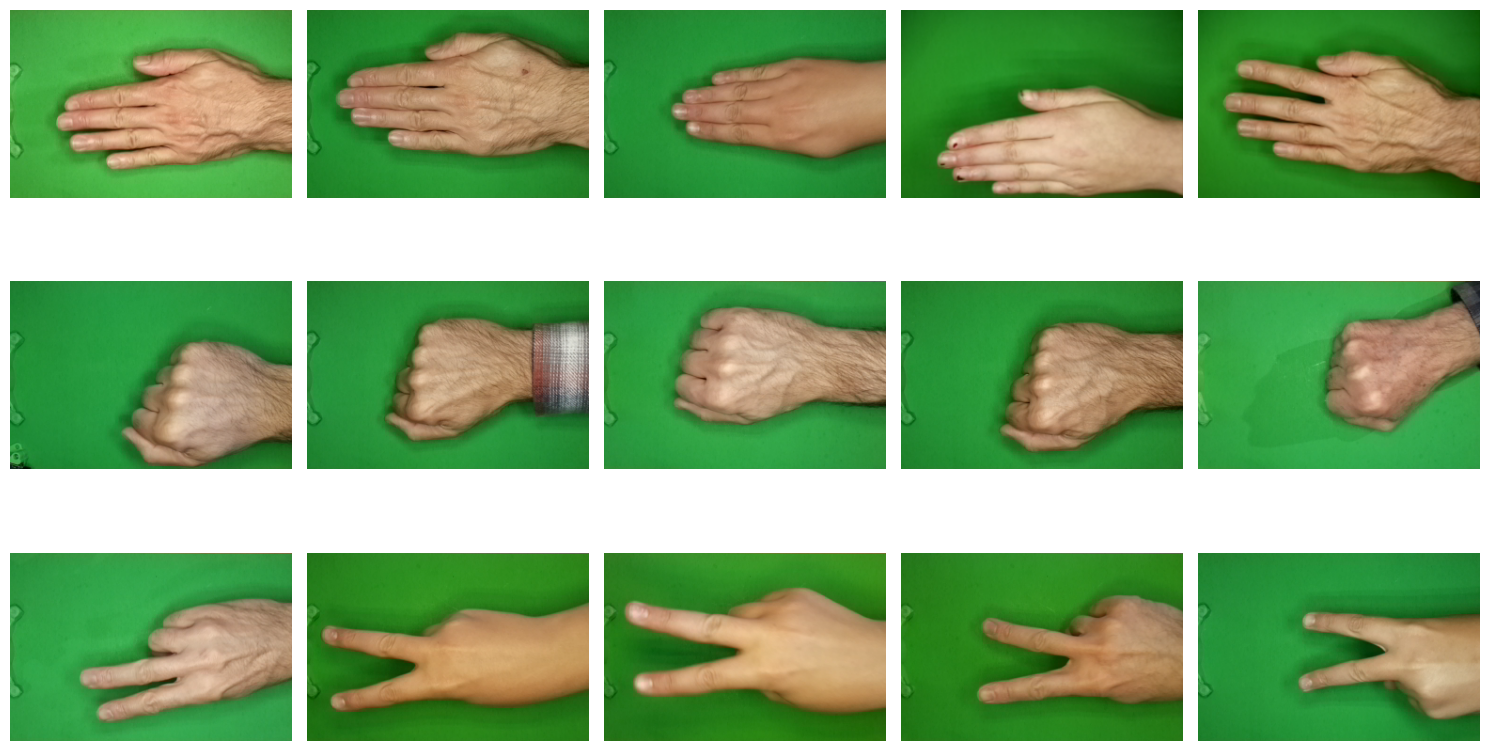

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i, class_name in enumerate(classes):
    class_path = os.path.join(data_path, class_name)
    image_files = os.listdir(class_path)[:5]
    
    for j, img_file in enumerate(image_files):
        img_path = os.path.join(class_path, img_file)
        img = Image.open(img_path).convert('RGB')
        axes[i, j].imshow(img)
        axes[i, j].axis('off')

plt.tight_layout()
plt.savefig('../reports/figures/sample_images.png', dpi=300, bbox_inches='tight')
plt.show()

## Image Dimensions Analysis

In [8]:
image_sizes = []

for class_name in classes:
    class_path = os.path.join(data_path, class_name)
    image_files = os.listdir(class_path)
    
    for img_file in image_files:
        img_path = os.path.join(class_path, img_file)
        img = Image.open(img_path)
        image_sizes.append(img.size)

df_sizes = pd.DataFrame(image_sizes, columns=['Width', 'Height'])

print(df_sizes.describe())
print(f"\n {df_sizes.mode().iloc[0].tolist()}")

        Width  Height
count  2188.0  2188.0
mean    300.0   200.0
std       0.0     0.0
min     300.0   200.0
25%     300.0   200.0
50%     300.0   200.0
75%     300.0   200.0
max     300.0   200.0

 [300, 200]
